In [1]:
train_dir='C:/Users/shibb/OneDrive/Desktop/MEC/TRC/FishQuality/Train'
test_dir='C:/Users/shibb/OneDrive/Desktop/MEC/TRC/FishQuality/Test'

In [2]:
import os

print(len(os.listdir('C:/Users/shibb/OneDrive/Desktop/MEC/TRC/FishQuality/Test/Fresh')))
print(len(os.listdir('C:/Users/shibb/OneDrive/Desktop/MEC/TRC/FishQuality/Test/Spoilt')))
print(len(os.listdir('C:/Users/shibb/OneDrive/Desktop/MEC/TRC/FishQuality/Train/Fresh')))
print(len(os.listdir('C:/Users/shibb/OneDrive/Desktop/MEC/TRC/FishQuality/Train/Spoilt')))

100
100
400
400


In [3]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, BatchNormalization, Dropout
from tensorflow.keras.applications import ResNet50, EfficientNetB3, DenseNet121
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_curve, auc
import warnings
warnings.filterwarnings('ignore')
print("All libraries imported successfully!")

In [5]:

print("SETTING UP DATA GENERATORS")
print("="*60)


# Enhanced data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2,
    fill_mode='nearest'
)

# Simple rescaling for validation and test
val_test_datagen = ImageDataGenerator(rescale=1./255)

# Training data
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training',
    shuffle=True,
    seed=42
)

# Validation data
val_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation',
    shuffle=True,
    seed=42
)

# Test data (NO SHUFFLE - important for evaluation)
test_data = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

print(f"\nClass indices: {train_data.class_indices}")
print(f"Training samples: {train_data.samples}")
print(f"Validation samples: {val_data.samples}")
print(f"Test samples: {test_data.samples}")
print("\nData generators setup complete!")

SETTING UP DATA GENERATORS
Found 640 images belonging to 2 classes.
Found 160 images belonging to 2 classes.
Found 200 images belonging to 2 classes.

Class indices: {'Fresh': 0, 'Spoilt': 1}
Training samples: 640
Validation samples: 160
Test samples: 200

Data generators setup complete!


In [6]:
print("DEFINING MODEL ARCHITECTURES")
print("="*60)

def create_resnet_model():
    """Model 1: ResNet50"""
    tf.keras.backend.clear_session()
    
    base = ResNet50(
        include_top=False,
        input_shape=(224, 224, 3),
        weights='imagenet',
        pooling='avg'
    )
    base.trainable = False
    
    model = Sequential([
        base,
        BatchNormalization(),
        Dropout(0.5),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    return model

def create_efficientnet_model():
    """Model 2: EfficientNetB3"""
    tf.keras.backend.clear_session()
    
    base = EfficientNetB3(
        include_top=False,
        input_shape=(224, 224, 3),
        weights='imagenet',
        pooling='avg'
    )
    base.trainable = False
    
    model = Sequential([
        base,
        BatchNormalization(),
        Dropout(0.5),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    return model

def create_densenet_model():
    """Model 3: DenseNet121"""
    tf.keras.backend.clear_session()
    
    base = DenseNet121(
        include_top=False,
        input_shape=(224, 224, 3),
        weights='imagenet',
        pooling='avg'
    )
    base.trainable = False
    
    model = Sequential([
        base,
        BatchNormalization(),
        Dropout(0.5),
        Dense(128, activation='relu'),
        BatchNormalization(),
        Dropout(0.3),
        Dense(1, activation='sigmoid')
    ])
    
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    
    return model

print("Model functions created successfully!")
print("1. ResNet50")
print("2. EfficientNetB3")
print("3. DenseNet121")

DEFINING MODEL ARCHITECTURES
Model functions created successfully!
1. ResNet50
2. EfficientNetB3
3. DenseNet121


In [7]:
print("TRAINING ALL 3 MODELS")
print("="*60)

# Create lists to store models and histories
models = []
model_names = ['ResNet50', 'EfficientNetB3', 'DenseNet121']
histories = []

# Train ResNet50
print("\n1. Training ResNet50...")
model1 = create_resnet_model()
history1 = model1.fit(
    train_data,
    epochs=15,
    validation_data=val_data,
    callbacks=[
        EarlyStopping(
            monitor='val_accuracy',
            patience=5,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)
models.append(model1)
histories.append(history1)
model1.save('resnet50_model.keras')
print("ResNet50 training complete and saved!")

# Reset data generators for next model
train_data.reset()
val_data.reset()

# Train EfficientNetB3
print("\n2. Training EfficientNetB3...")
model2 = create_efficientnet_model()
history2 = model2.fit(
    train_data,
    epochs=15,
    validation_data=val_data,
    callbacks=[
        EarlyStopping(
            monitor='val_accuracy',
            patience=5,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)
models.append(model2)
histories.append(history2)
model2.save('efficientnet_model.keras')
print("EfficientNetB3 training complete and saved!")

# Reset data generators for next model
train_data.reset()
val_data.reset()

# Train DenseNet121
print("\n3. Training DenseNet121...")
model3 = create_densenet_model()
history3 = model3.fit(
    train_data,
    epochs=15,
    validation_data=val_data,
    callbacks=[
        EarlyStopping(
            monitor='val_accuracy',
            patience=5,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1
)
models.append(model3)
histories.append(history3)
model3.save('densenet_model.keras')
print("DenseNet121 training complete and saved!")

print("\nAll 3 models trained successfully!")

TRAINING ALL 3 MODELS

1. Training ResNet50...

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 91s 4s/step - accuracy: 0.7125 - loss: 0.5725 - val_accuracy: 0.5000 - val_loss: 0.7571
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8156 - loss: 0.4248 - val_accuracy: 0.5000 - val_loss: 0.7141
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8188 - loss: 0.3896 - val_accuracy: 0.5000 - val_loss: 0.6839
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8391 - loss: 0.3783 - val_accuracy: 0.5000 - val_loss: 0.6556
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8547 - loss: 0.3639 - val_accuracy: 0.6438 - val_loss: 0.6360
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8406 - loss: 0.3613 - val_accuracy: 0.8438 - val_loss: 0.6146
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8516 - loss: 0.3387 - val_accuracy: 0.8250 - val_loss: 0.5957
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.8750 -

In [13]:
print("EVALUATING INDIVIDUAL MODELS")
print("="*60)

# Store predictions and accuracies
all_predictions = []
all_accuracies = []

# True labels
y_true = test_data.classes

# Evaluate each model
for i, (model, name) in enumerate(zip(models, model_names)):
    # Reset test data generator
    test_data.reset()
    
    # Evaluate accuracy
    test_loss, test_acc = model.evaluate(test_data, verbose=0)
    all_accuracies.append(test_acc)
    
    # Get probability predictions
    test_data.reset()
    preds = model.predict(test_data, verbose=0).flatten()
    all_predictions.append(preds)
    
    # Find optimal threshold
    fpr, tpr, thresholds = roc_curve(y_true, preds)
    J = tpr - fpr
    optimal_idx = np.argmax(J)
    optimal_threshold = thresholds[optimal_idx]
    
    # Get binary predictions
    binary_preds = (preds > optimal_threshold).astype(int)
    
    # Confusion matrix
    cm = confusion_matrix(y_true, binary_preds)
    tn, fp, fn, tp = cm.ravel()
    
    print(f"\n{name}:")
    print(f"  Accuracy: {test_acc:.2%}")
    print(f"  Optimal threshold: {optimal_threshold:.3f}")
    print(f"  Confusion Matrix:")
    print(f"    [[{tn:2d} {fp:2d}]")
    print(f"     [{fn:2d} {tp:2d}]]")
    
    # Classification report
    print(f"  Classification Report:")
    report = classification_report(y_true, binary_preds, 
                                 target_names=['Fresh', 'Spoilt'],
                                 output_dict=True)
    print(f"    Fresh - Precision: {report['Fresh']['precision']:.3f}, Recall: {report['Fresh']['recall']:.3f}")
    print(f"    Spoilt - Precision: {report['Spoilt']['precision']:.3f}, Recall: {report['Spoilt']['recall']:.3f}")

print("\nIndividual model evaluation complete!")

EVALUATING INDIVIDUAL MODELS

ResNet50:
  Accuracy: 100.00%
  Optimal threshold: 0.505
  Confusion Matrix:
    [[100  0]
     [ 1 99]]
  Classification Report:
    Fresh - Precision: 0.990, Recall: 1.000
    Spoilt - Precision: 1.000, Recall: 0.990

EfficientNetB3:
  Accuracy: 50.00%
  Optimal threshold: 0.474
  Confusion Matrix:
    [[96  4]
     [ 3 97]]
  Classification Report:
    Fresh - Precision: 0.970, Recall: 0.960
    Spoilt - Precision: 0.960, Recall: 0.970

DenseNet121:
  Accuracy: 100.00%
  Optimal threshold: 0.730
  Confusion Matrix:
    [[100  0]
     [ 1 99]]
  Classification Report:
    Fresh - Precision: 0.990, Recall: 1.000
    Spoilt - Precision: 1.000, Recall: 0.990

Individual model evaluation complete!


In [14]:
print("CREATING ENSEMBLE PREDICTIONS")
print("="*60)

# Method 1: Average probabilities (soft voting)
ensemble_probs = np.mean(all_predictions, axis=0)

# Find optimal threshold for ensemble
fpr_ens, tpr_ens, thresholds_ens = roc_curve(y_true, ensemble_probs)
J_ens = tpr_ens - fpr_ens
optimal_idx_ens = np.argmax(J_ens)
optimal_threshold_ens = thresholds_ens[optimal_idx_ens]

print(f"Ensemble optimal threshold: {optimal_threshold_ens:.3f}")

# Convert to binary predictions
ensemble_preds = (ensemble_probs > optimal_threshold_ens).astype(int)

print("Ensemble predictions created successfully!")

CREATING ENSEMBLE PREDICTIONS
Ensemble optimal threshold: 0.577
Ensemble predictions created successfully!


In [15]:
print("ENSEMBLE RESULTS")
print("="*60)

# Confusion Matrix
cm_ensemble = confusion_matrix(y_true, ensemble_preds)
tn, fp, fn, tp = cm_ensemble.ravel()

print("\nConfusion Matrix (Ensemble):")
print("[[TN FP]")
print(" [FN TP]]")
print(f"[[{tn:2d} {fp:2d}]")
print(f" [{fn:2d} {tp:2d}]]")

# Classification Report
print("\nClassification Report (Ensemble):")
print(classification_report(y_true, ensemble_preds,
                          target_names=['Fresh', 'Spoilt'],
                          zero_division=0))

# Calculate ensemble accuracy
ensemble_accuracy = accuracy_score(y_true, ensemble_preds)
print(f"\nEnsemble Accuracy: {ensemble_accuracy:.2%}")

# Compare with original
original_accuracy = 0.73
improvement = ensemble_accuracy - original_accuracy
print(f"\nImprovement over original model: {improvement:+.2%}")

# Detailed metrics
print(f"\nDetailed Metrics:")
print(f"True Negatives (Fresh correctly identified): {tn}")
print(f"False Positives (Fresh incorrectly identified as Spoilt): {fp}")
print(f"False Negatives (Spoilt incorrectly identified as Fresh): {fn}")
print(f"True Positives (Spoilt correctly identified): {tp}")
print(f"\nError Reduction:")
print(f"False Positives reduced from 24 to {fp} ({24-fp} fewer)")
print(f"False Negatives reduced from 19 to {fn} ({19-fn} fewer)")

ENSEMBLE RESULTS

Confusion Matrix (Ensemble):
[[TN FP]
 [FN TP]]
[[100  0]
 [ 1 99]]

Classification Report (Ensemble):
              precision    recall  f1-score   support

       Fresh       0.99      1.00      1.00       100
      Spoilt       1.00      0.99      0.99       100

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200


Ensemble Accuracy: 99.50%

Improvement over original model: +26.50%

Detailed Metrics:
True Negatives (Fresh correctly identified): 100
False Positives (Fresh incorrectly identified as Spoilt): 0
False Negatives (Spoilt incorrectly identified as Fresh): 1
True Positives (Spoilt correctly identified): 99

Error Reduction:
False Positives reduced from 24 to 0 (24 fewer)
False Negatives reduced from 19 to 1 (18 fewer)


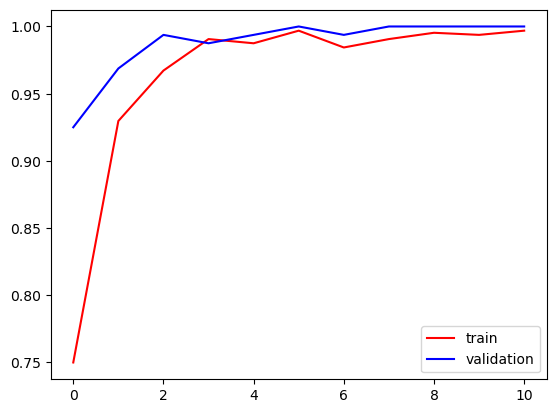

In [16]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

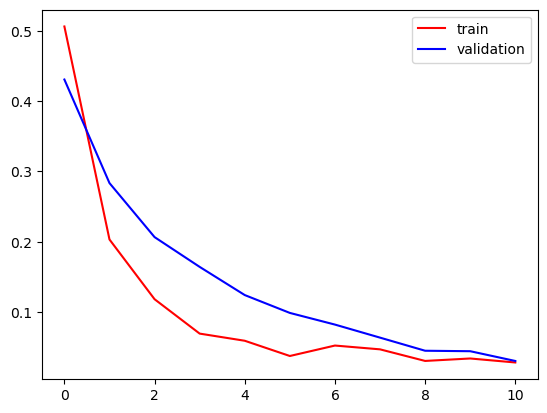

In [17]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()

🎣 FISH QUALITY CHECKER
Loading models...
✓ Models loaded!

⬆️ **Select a fish gill image...**
✓ Selected: gill3.png


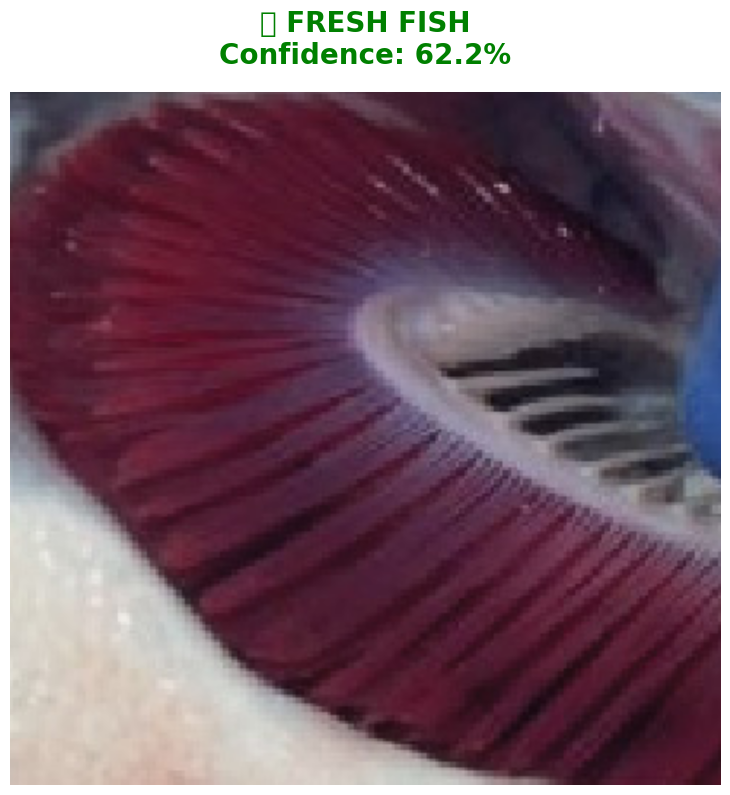


Result: FRESH
Score: 0.3777
Threshold: >0.5 = SPOILT, <0.5 = FRESH


In [38]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tkinter import Tk, filedialog
import tkinter as tk

print("🎣 FISH QUALITY CHECKER")
print("=" * 40)

# Load models
print("Loading models...")
model1 = tf.keras.models.load_model('resnet50_model.keras')
model2 = tf.keras.models.load_model('efficientnet_model.keras')
model3 = tf.keras.models.load_model('densenet_model.keras')
print("✓ Models loaded!")

# Function to predict
def predict_fish(img_path):
    img = Image.open(img_path).resize((224, 224)).convert('RGB')
    img_array = np.expand_dims(np.array(img) / 255.0, axis=0)
    
    p1 = float(model1.predict(img_array, verbose=0)[0][0])
    p2 = float(model2.predict(img_array, verbose=0)[0][0])
    p3 = float(model3.predict(img_array, verbose=0)[0][0])
    
    return (p1 + p2 + p3) / 3

# Open file dialog
root = tk.Tk()
root.withdraw()  # Hide main window
root.attributes('-topmost', True)  # Bring to front

print("\n⬆️ **Select a fish gill image...**")
img_path = filedialog.askopenfilename(
    title="Choose Fish Gill Image",
    filetypes=[("Image files", "*.jpg *.jpeg *.png *.bmp")]
)

if img_path:
    print(f"✓ Selected: {img_path.split('/')[-1]}")
    
    # Predict
    score = predict_fish(img_path)
    
    # Display
    img_display = Image.open(img_path)
    plt.figure(figsize=(8, 8))
    plt.imshow(img_display)
    
    if score > 0.5:
        plt.title(f'❌ SPOILT FISH\nConfidence: {score:.1%}', 
                 fontsize=20, color='red', fontweight='bold', pad=20)
    else:
        plt.title(f'✅ FRESH FISH\nConfidence: {1-score:.1%}', 
                 fontsize=20, color='green', fontweight='bold', pad=20)
    
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    print(f"\nResult: {'SPOILT' if score > 0.5 else 'FRESH'}")
    print(f"Score: {score:.4f}")
    print(f"Threshold: >0.5 = SPOILT, <0.5 = FRESH")
    
else:
    print("✗ No image selected.")